# Customer Churn Analysis — Telco 

**Business question:** *Which customers are at risk of leaving, and what should the company do?*

Data: 7,043 customers of a US telecom company (IBM Telco Customer Churn dataset). One row = one customer. `Churn = Yes` means the customer left last month.

## 1. Load the data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/telco_churn.csv")
print(df.shape)   # (rows, columns)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Clean the data

`TotalCharges` should be a number, but pandas read it as text. Why? 11 customers have a blank value.
These customers have `tenure = 0`: they just signed up, so they haven't paid anything yet.
We convert the column to numbers; the blanks become `NaN` (missing), and we replace them with 0.

In [2]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing TotalCharges:", df["TotalCharges"].isna().sum())
print(df.loc[df["TotalCharges"].isna(), "tenure"].unique())   # all have tenure 0

df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Churn as a number: 1 = left, 0 = stayed. The mean of this column = churn rate.
df["churned"] = (df["Churn"] == "Yes").astype(int)
df.duplicated("customerID").sum()   # 0 duplicates

Missing TotalCharges: 11
[0]


np.int64(0)

## 3. How big is the problem?

In [3]:
churn_rate = df["churned"].mean()
lost_revenue = df.loc[df["churned"] == 1, "MonthlyCharges"].sum()

print(f"Churn rate: {churn_rate:.1%}")
print(f"Customers who left: {df['churned'].sum():,}")
print(f"Monthly revenue lost: ${lost_revenue:,.0f}")

Churn rate: 26.5%
Customers who left: 1,869
Monthly revenue lost: $139,131


**Result:** about 1 customer in 4 left (26.5%), taking about **$139,000 of monthly revenue** with them.

## 4. Who leaves?

We compare the churn rate across groups. The helper function below does it for any column.

In [4]:
def churn_by(column):
    """Churn rate and number of customers for each value of a column."""
    return (df.groupby(column)["churned"]
              .agg(churn_rate="mean", customers="size")
              .sort_values("churn_rate", ascending=False))

BLUE, INK, MUTED = "#2a78d6", "#0b0b0b", "#52514e"

def bar_chart(table, title, filename):
    fig, ax = plt.subplots(figsize=(7, 3.2))
    bars = ax.barh(table.index.astype(str), table["churn_rate"] * 100, color=BLUE, height=0.6)
    ax.invert_yaxis()
    ax.bar_label(bars, labels=[f"{v:.1%}" for v in table["churn_rate"]], padding=4, color=INK)
    ax.axvline(churn_rate * 100, color=MUTED, linestyle="--", linewidth=1)
    ax.text(churn_rate * 100, len(table) - 0.55, f" average {churn_rate:.1%}", color=MUTED, fontsize=9, va="bottom")
    ax.set_xlabel("Churn rate (%)", color=MUTED)
    ax.set_title(title, loc="left", color=INK, fontsize=12, pad=10)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=MUTED)
    fig.tight_layout()
    fig.savefig(f"charts/{filename}.png", dpi=150)
    plt.show()

### 4a. Contract type

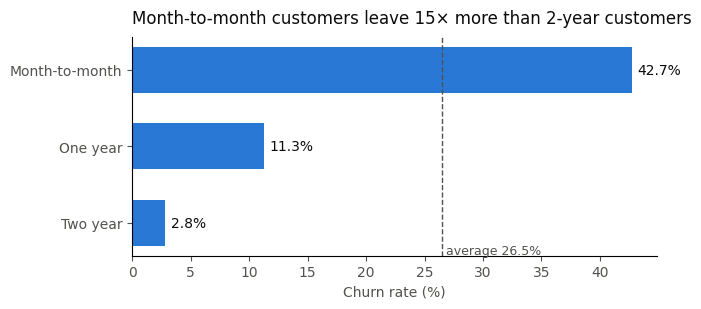

,churn_rate,customers
Contract,,
Month-to-month,0.427097,3875
One year,0.112695,1473
Two year,0.028319,1695


In [5]:
by_contract = churn_by("Contract")
bar_chart(by_contract, "Month-to-month customers leave 15× more than 2-year customers", "churn_by_contract")
by_contract

### 4b. Tenure (how long the customer has been with us)

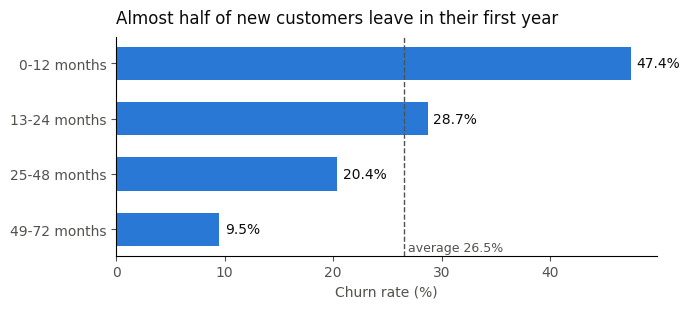

,churn_rate,customers
tenure_group,,
0-12 months,0.474382,2186
13-24 months,0.287109,1024
25-48 months,0.203890,1594
49-72 months,0.095132,2239


In [6]:
df["tenure_group"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                            labels=["0-12 months", "13-24 months", "25-48 months", "49-72 months"])
by_tenure = df.groupby("tenure_group", observed=True)["churned"].agg(churn_rate="mean", customers="size")
bar_chart(by_tenure, "Almost half of new customers leave in their first year", "churn_by_tenure")
by_tenure

### 4c. Payment method

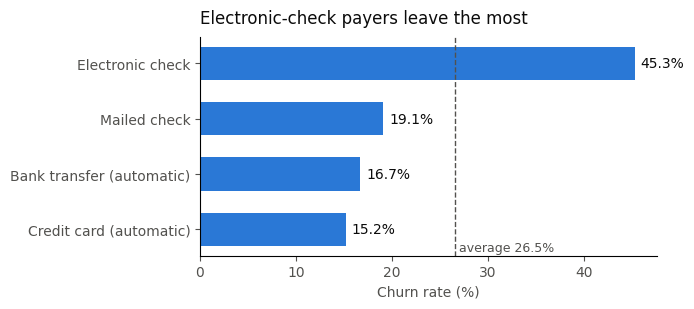

,churn_rate,customers
PaymentMethod,,
Electronic check,0.452854,2365
Mailed check,0.191067,1612
Bank transfer (automatic),0.167098,1544
Credit card (automatic),0.152431,1522


In [7]:
by_payment = churn_by("PaymentMethod")
bar_chart(by_payment, "Electronic-check payers leave the most", "churn_by_payment")
by_payment

### 4d. Internet service

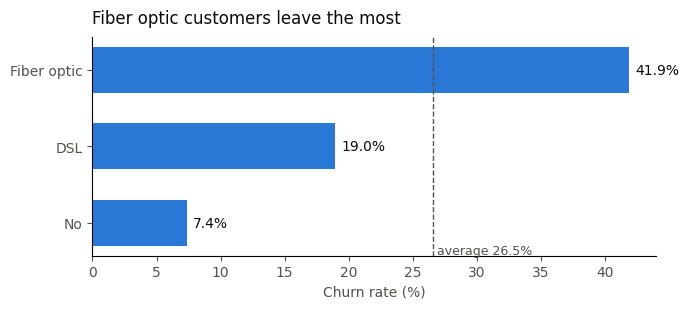

,churn_rate,customers
InternetService,,
Fiber optic,0.418928,3096
DSL,0.189591,2421
No,0.074050,1526


In [8]:
by_internet = churn_by("InternetService")
bar_chart(by_internet, "Fiber optic customers leave the most", "churn_by_internet")
by_internet

## 5. Part 1 summary

| Group | Churn rate |
|---|---|
| Month-to-month contract | 42.7% |
| Two-year contract | 2.8% |
| Tenure 0–12 months | 47.4% |
| Electronic check | 45.3% |
| Fiber optic | 41.9% |
| **All customers** | **26.5%** |

**Profile of a customer at risk:** new, on a month-to-month contract, paying by electronic check, with fiber optic.

⚠️ These groups overlap (many new customers are also on month-to-month contracts). In Part 2, a logistic regression will measure the effect of each factor *at the same time*.

## Part 2 — Which factors matter most? (logistic regression)

In Part 1, each factor was studied alone. But the groups overlap: new customers are also often on month-to-month contracts.
A **logistic regression** measures the effect of each factor **while holding the others constant**, and gives each customer a **probability of leaving** (between 0 and 1).

### 6. Prepare the variables
A model only understands numbers, so we turn text columns into 0/1 columns (`get_dummies`).
`drop_first=True` removes one category per column: it becomes the **reference** that the others are compared to
(e.g. *Month-to-month* for Contract, *Bank transfer* for PaymentMethod, *DSL* for InternetService).

In [9]:
# PART2
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score, confusion_matrix

# Readable units: tenure in years, monthly charges per $10
df["tenure_years"] = df["tenure"] / 12
df["monthly_charges_per_10"] = df["MonthlyCharges"] / 10
df["has_tech_support"] = (df["TechSupport"] == "Yes").astype(int)
df["has_online_security"] = (df["OnlineSecurity"] == "Yes").astype(int)

features = ["Contract", "tenure_years", "PaymentMethod", "InternetService", "monthly_charges_per_10",
            "has_tech_support", "has_online_security", "SeniorCitizen", "PaperlessBilling"]

X = pd.get_dummies(df[features], drop_first=True, dtype=int)   # inputs
y = df["churned"]                                               # what we predict
X.columns.tolist()

['tenure_years',
 'monthly_charges_per_10',
 'has_tech_support',
 'has_online_security',
 'SeniorCitizen',
 'Contract_One year',
 'Contract_Two year',
 'PaymentMethod_Credit card (automatic)',
 'PaymentMethod_Electronic check',
 'PaymentMethod_Mailed check',
 'InternetService_Fiber optic',
 'InternetService_No',
 'PaperlessBilling_Yes']

### 7. Train / test split
We train the model on 75% of customers and test it on the other 25%, which it has **never seen**.
This checks that the model works on new customers, not just the ones it memorised.
`stratify=y` keeps the same churn rate (26.5%) in both parts.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

model = LogisticRegression(max_iter=2000)
model.fit(X_train, y_train)

pred = model.predict(X_test)               # 0 or 1
proba = model.predict_proba(X_test)[:, 1]  # probability of leaving

### 8. Is the model any good?
**Baseline:** a "model" that always says *stays* would already be right 73.5% of the time. Our model must beat that.

In [11]:
baseline = 1 - y_test.mean()
print(f"Baseline accuracy (always 'stays'): {baseline:.1%}")
print(f"Model accuracy:                     {accuracy_score(y_test, pred):.1%}")
print(f"Recall (share of leavers detected): {recall_score(y_test, pred):.1%}")
print(f"ROC AUC:                            {roc_auc_score(y_test, proba):.2f}")
pd.DataFrame(confusion_matrix(y_test, pred),
             index=["Actually stayed", "Actually left"], columns=["Predicted stays", "Predicted leaves"])

Baseline accuracy (always 'stays'): 73.5%
Model accuracy:                     79.6%
Recall (share of leavers detected): 52.7%
ROC AUC:                            0.84


,Predicted stays,Predicted leaves
Actually stayed,1156,138
Actually left,221,246


**How to read this:**
- Accuracy beats the baseline (≈80% vs 73.5%).
- **ROC AUC ≈ 0.84:** if you take one leaver and one stayer at random, the model gives the higher risk to the leaver 84% of the time (0.5 = random guess, 1 = perfect).
- Recall ≈ 53%: with the default 50% threshold, the model detects about half of the leavers. That's why, in step 10, we **rank** customers by risk instead of using a yes/no answer.

### 9. Which factors matter? (odds ratios)
`exp(coefficient)` = **odds ratio**. Above 1 → increases the risk of leaving; below 1 → reduces it.
Example: 0.28 means the odds of leaving are multiplied by 0.28 (−72%), all other factors being equal.

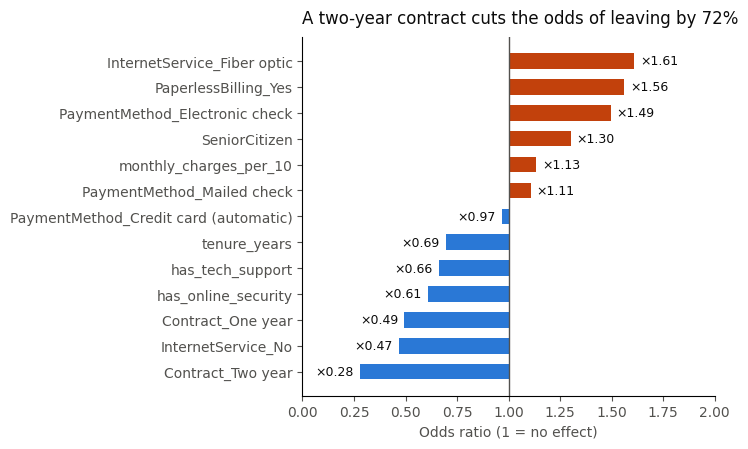

Contract_Two year                        0.28
InternetService_No                       0.47
Contract_One year                        0.49
has_online_security                      0.61
has_tech_support                         0.66
tenure_years                             0.69
PaymentMethod_Credit card (automatic)    0.97
PaymentMethod_Mailed check               1.11
monthly_charges_per_10                   1.13
SeniorCitizen                            1.30
PaymentMethod_Electronic check           1.49
PaperlessBilling_Yes                     1.56
InternetService_Fiber optic              1.61
Name: odds_ratio, dtype: float64

In [12]:
import numpy as np
odds = (pd.Series(np.exp(model.coef_[0]), index=X.columns)
          .sort_values()
          .rename("odds_ratio"))

fig, ax = plt.subplots(figsize=(7.5, 4.6))
colors = [BLUE if v < 1 else "#c2410c" for v in odds]
ax.barh(odds.index, odds.values - 1, left=1, color=colors, height=0.6)
ax.axvline(1, color=MUTED, linewidth=1)
for i, v in enumerate(odds.values):
    ax.text(v + (0.03 if v >= 1 else -0.03), i, f"×{v:.2f}", va="center",
            ha="left" if v >= 1 else "right", color=INK, fontsize=9)
ax.set_xlim(0, 2.0)
ax.set_xlabel("Odds ratio (1 = no effect)", color=MUTED)
ax.set_title("A two-year contract cuts the odds of leaving by 72%", loc="left", color=INK, fontsize=12, pad=10)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.tick_params(colors=MUTED)
fig.tight_layout(); fig.savefig("charts/odds_ratios.png", dpi=150); plt.show()
odds.round(2)

### 10. Who should the retention team call first?
We rank test customers by their predicted probability and look at the **20% most at risk**.

In [13]:
ranked = pd.DataFrame({"left": y_test.values, "risk": proba,
                       "monthly_charges": df.loc[X_test.index, "MonthlyCharges"].values})
ranked = ranked.sort_values("risk", ascending=False)
top = ranked.head(int(len(ranked) * 0.20))

print(f"Customers in the top 20%:          {len(top)}")
print(f"Churn rate in the top 20%:         {top['left'].mean():.1%}  (vs {y_test.mean():.1%} overall)")
print(f"Share of all leavers they contain: {top['left'].sum() / ranked['left'].sum():.1%}")
print(f"Monthly revenue of the leavers in this group: ${top.loc[top['left'] == 1, 'monthly_charges'].sum():,.0f}")

Customers in the top 20%:          352
Churn rate in the top 20%:         64.5%  (vs 26.5% overall)
Share of all leavers they contain: 48.6%
Monthly revenue of the leavers in this group: $18,852


## Part 3 — What should the company do?

### 11. How much could a retention campaign save?
The retention team calls the 20% of customers the model ranks as most at risk.
We don't know how many of them a campaign would keep, so we test three **assumptions** (10%, 20%, 30% of the leavers kept).

In [14]:
# PART3
lost_top = top.loc[top["left"] == 1, "monthly_charges"].sum()   # test set = 25% of customers
scale = len(df) / len(ranked)                                   # ≈ 4, to estimate for the whole base

print(f"Monthly revenue of leavers in the top 20% (whole base, estimated): ${lost_top * scale:,.0f}")
for kept in [0.10, 0.20, 0.30]:
    saved = lost_top * scale * kept
    print(f"If the campaign keeps {kept:.0%} of them: ${saved:,.0f}/month, about ${saved * 12:,.0f}/year")

Monthly revenue of leavers in the top 20% (whole base, estimated): $75,397
If the campaign keeps 10% of them: $7,540/month, about $90,476/year
If the campaign keeps 20% of them: $15,079/month, about $180,952/year
If the campaign keeps 30% of them: $22,619/month, about $271,428/year


### 12. Recommendations

| # | Finding | Recommendation |
|---|---|---|
| 1 | The 20% riskiest customers contain **~49% of all leavers** (64.5% of them leave) | Give the retention team a **monthly risk list** from the model and call these customers first |
| 2 | Month-to-month: **42.7%** churn vs **2.8%** on 2-year contracts | Offer a **discount to switch to a 1-year contract**, starting with high-risk customers |
| 3 | First year: **47.4%** churn | Build an **onboarding programme** for new customers (check-in call, setup help in the first 3 months) |
| 4 | Electronic check: **45.3%** churn vs ~15–17% for automatic payments | Encourage **automatic payment** (small one-off credit) |
| 5 | Fiber optic: **41.9%** churn, odds ×1.61 even at the same price | **Investigate fiber service quality** (outages, speed, support tickets) |
| 6 | Tech support (×0.66) and online security (×0.61) go with lower churn | **Bundle** these services in retention offers |

### 13. Limits
- **Correlation is not causation.** Customers who choose long contracts may simply be more satisfied already. Each recommendation should be **tested with an A/B test** before a full rollout.
- The savings in step 11 are **scenarios**, not predictions: the real retention rate is unknown.
- One snapshot of one company (IBM sample data): no dates, so no trend over time.